# Домашняя работа 3. Как модель учится узнавать произнесённые цифры

Михаил Черемисин

Я сравнил три способа научить нейросеть описывать звук: с готовыми ответами, через сопоставление двух представлений одной записи и через неконтрастный метод VICReg. Использован полный AudioMNIST: 30 000 записей цифр от 60 дикторов. Лучшую точность в данном эксперименте показало обучение с учителем: 98.98% на 6000 записях новых дикторов.

Решение подготовлено с помощью ИИ. Модели действительно обучены; результаты получены вычислением. Результаты относятся к этому разбиению и одной инициализации. Официальная сдача и оценка не подтверждены.

[Исходное задание](https://github.com/DeepLearningSchool/Speech/blob/main/week_03_speech_ssl/Homework/SSL_Homework.ipynb).

## Воспроизведение

В чистом окружении скачивается полный AudioMNIST, около 1 ГБ архива, и выполняется обучение. Рекомендуется GPU. Если рядом уже есть checkpoint, они загружаются и результаты проверки вычисляются заново; повторное обучение не выдаётся за новый эксперимент. Для нового обучения установите RUN_FRESH=True. Локальное обучение уже выполнено, его журналы и checkpoint сохранены в files.

In [1]:
from pathlib import Path
import sys, os, importlib.util, subprocess, json, hashlib, urllib.request, zipfile
WORKSPACE_ROOT=next((p for p in [Path.cwd(),*Path.cwd().parents] if (p/'.study-audit').exists()),Path.cwd())
for name in ['series-runtime','speech-runtime','speech2-runtime','pytorch-runtime','pytorch-cuda-runtime']:
    directory=WORKSPACE_ROOT/'.study-audit'/name
    if directory.exists():sys.path.insert(0,str(directory))
required={'numpy':'numpy','scipy':'scipy','soundfile':'soundfile','sklearn':'scikit-learn','matplotlib':'matplotlib','torch':'torch'}
missing=[package for module,package in required.items() if importlib.util.find_spec(module) is None]
if missing:subprocess.check_call([sys.executable,'-m','pip','install',*missing])
WORK_FILES=Path.cwd().parent/'files' if (Path.cwd().parent/'files/original.ipynb').exists() else Path.cwd()/'speech_hw3_work'
WORK_FILES.mkdir(exist_ok=True); (WORK_FILES/'data').mkdir(exist_ok=True)
original=WORK_FILES/'original.ipynb'
if not original.exists():
    original.write_bytes(urllib.request.urlopen('https://raw.githubusercontent.com/DeepLearningSchool/Speech/3bd6ad5fb11e4b936fa534e5bbe66462d816d831/week_03_speech_ssl/Homework/SSL_Homework.ipynb',timeout=60).read())
assert hashlib.sha256(original.read_bytes()).hexdigest()=='992b2e4fd8dad9db37cc3b040779fcc7fc62bbe3dff5a6b426fa677473b08188'
print('Исходное задание проверено по SHA256; рабочая папка:',WORK_FILES)


Исходное задание проверено по SHA256; рабочая папка: C:\Users\expla\My Drive\UrFU\Магистратура\(2) 🧠 Искусственный интеллект и нейронные сети\DLS Speech\Homework 3 - Self-Supervised Audio\files


In [2]:
"""DLS Speech HW3: full AudioMNIST, fixed speaker split, three training paradigms."""
from pathlib import Path
import os, sys, json, time, random, hashlib, argparse, copy
ROOT=WORKSPACE_ROOT
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader,Dataset
import soundfile as sf
from scipy.signal import resample_poly
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,log_loss,confusion_matrix,f1_score

HERE=WORK_FILES
DATA=HERE/'data';OUT=HERE/'experiments';OUT.mkdir(exist_ok=True)
SEED=42;SR=16000;N=16000;BATCH=64;WIDTH=8
torch.set_num_threads(4)
try:torch.set_num_interop_threads(1)
except RuntimeError:pass
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type=='cuda':
    torch.cuda.set_per_process_memory_fraction(0.25)
    torch.backends.cudnn.benchmark=False
    torch.backends.cudnn.deterministic=True
def seed(value=SEED):
    random.seed(value);np.random.seed(value);torch.manual_seed(value)

def mel_basis():
    # Same HTK mel definition as torchaudio's seminar defaults, n_fft=400.
    f=np.linspace(0,SR/2,201)
    hz=700*(10**(np.linspace(0,2595*np.log10(1+SR/2/700),66)/2595)-1)
    return torch.tensor(np.maximum(0,np.minimum((f[None,:]-hz[:-2,None])/(hz[1:-1,None]-hz[:-2,None]),(hz[2:,None]-f[None,:])/(hz[2:,None]-hz[1:-1,None]))),dtype=torch.float32)

def prepare():
    if (DATA/'prepared.json').exists():return
    started=time.monotonic()
    wavs=sorted((DATA/'AudioMNIST-master/data').glob('*/*.wav'))
    assert len(wavs)==30000,len(wavs)
    waves=np.lib.format.open_memmap(DATA/'waves.npy',mode='w+',dtype=np.float16,shape=(len(wavs),N))
    specs=np.lib.format.open_memmap(DATA/'specs.npy',mode='w+',dtype=np.float16,shape=(len(wavs),64,81))
    labels=[];speakers=[];manifest=[];trimmed=0
    basis=mel_basis();window=torch.hann_window(400)
    for start in range(0,len(wavs),128):
        chunk=[]
        for p in wavs[start:start+128]:
            y,sr=sf.read(p,dtype='float32');y=y.mean(axis=1) if y.ndim==2 else y
            y=resample_poly(y,SR//np.gcd(SR,sr),sr//np.gcd(SR,sr)).astype(np.float32)
            if len(y)>N: trimmed+=1;y=y[(len(y)-N)//2:(len(y)-N)//2+N]
            y=y-y.mean();y=y/max(float(np.max(np.abs(y))),1e-6)
            y=np.pad(y,(0,N-len(y)));chunk.append(y)
            digit,speaker,_=p.stem.split('_');labels.append(int(digit));speakers.append(int(speaker))
            manifest.append({'path':str(p.relative_to(DATA)).replace('\\','/'),'sha256':hashlib.sha256(p.read_bytes()).hexdigest()})
        w=torch.tensor(np.stack(chunk));power=torch.stft(w,n_fft=400,hop_length=200,window=window,return_complex=True).abs().square()
        s=torch.log(basis@power+1e-8);s=(s-s.mean((1,2),keepdim=True))/(s.std((1,2),keepdim=True)+1e-5)
        waves[start:start+len(chunk)]=w.numpy().astype(np.float16);specs[start:start+len(chunk)]=s.numpy().astype(np.float16)
        if start%2048==0:print(json.dumps({'preprocessed':start+len(chunk),'total':len(wavs),'seconds':round(time.monotonic()-started)}),flush=True)
    waves.flush();specs.flush();np.save(DATA/'labels.npy',np.array(labels));np.save(DATA/'speakers.npy',np.array(speakers))
    (HERE/'data-manifest.json').write_text(json.dumps(manifest),encoding='utf-8')
    summary={'recordings':len(wavs),'train_speakers':list(range(1,49)),'validation_speakers':list(range(49,61)),
             'train_count':24000,'validation_count':6000,'sample_rate':SR,'samples_per_recording':N,'trimmed_recordings':trimmed,
             'n_mels':64,'n_fft':400,'hop_length':200,'storage':'float16, converted to float32 for training','preparation_seconds':time.monotonic()-started}
    (DATA/'prepared.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')

class AudioData(Dataset):
    def __init__(self,training):
        self.wave=np.load(DATA/'waves.npy',mmap_mode='r');self.spec=np.load(DATA/'specs.npy',mmap_mode='r')
        self.labels=np.load(DATA/'labels.npy');sp=np.load(DATA/'speakers.npy')
        self.ids=np.flatnonzero(sp<=48 if training else sp>=49)
    def __len__(self):return len(self.ids)
    def __getitem__(self,i):
        j=self.ids[i]
        return torch.tensor(self.wave[j].astype(np.float32))[None,:],torch.tensor(self.spec[j].astype(np.float32))[None,:,:],int(self.labels[j])

class Block(nn.Module):
    def __init__(self,dim,cin,cout,stride):
        super().__init__();Conv=getattr(nn,f'Conv{dim}d');BN=getattr(nn,f'BatchNorm{dim}d')
        self.conv1=Conv(cin,cout,1,bias=True);self.bn1=BN(cout)
        self.conv2=Conv(cout,cout,3,stride=stride,padding=1,bias=True);self.bn2=BN(cout)
        self.skip=nn.Sequential(Conv(cin,cout,1,stride=stride,bias=False),BN(cout)) if stride!=1 else nn.Identity()
    def forward(self,x):
        y=self.bn2(self.conv2(F.relu(self.bn1(self.conv1(x)))))
        return F.relu(y+self.skip(x))

class Encoder(nn.Module):
    """Seminar residual design [2,2,2,2], reduced channel width for CPU."""
    def __init__(self,dim):
        super().__init__();Conv=getattr(nn,f'Conv{dim}d');BN=getattr(nn,f'BatchNorm{dim}d');Pool=getattr(nn,f'MaxPool{dim}d')
        self.stem=nn.Sequential(Conv(1,WIDTH,7,stride=2,padding=3,bias=False),BN(WIDTH),nn.ReLU(),Pool(3,stride=2,padding=1))
        blocks=[];cin=WIDTH
        for stage in range(4):
            cout=WIDTH*2**stage
            for block in range(2):
                stride=2 if stage>0 and block==0 else 1
                blocks.append(Block(dim,cin,cout,stride));cin=cout
        self.layers=nn.Sequential(*blocks)
    def forward(self,x):
        x=self.layers(self.stem(x));return x.flatten(2).mean(-1)

def projector(final_bias=True):
    return nn.Sequential(nn.Linear(WIDTH*8,256),nn.BatchNorm1d(256),nn.ReLU(),nn.Linear(256,256),nn.BatchNorm1d(256),nn.ReLU(),nn.Linear(256,128,bias=final_bias))

class MultiFormat(nn.Module):
    def __init__(self,mode):
        super().__init__();self.wave=Encoder(1);self.spec=Encoder(2)
        self.mode=mode
        if mode=='supervised':self.head=nn.Linear(WIDTH*16,10)
        if mode=='infonce':self.shared_projector=projector()
        if mode=='vicreg':self.wave_projector=projector(False);self.spec_projector=projector(False)
    def features(self,w,s):return self.wave(w),self.spec(s)
    def forward(self,w,s):
        a,b=self.features(w,s)
        if self.mode=='supervised':return self.head(torch.cat((a,b),1))
        if self.mode=='infonce':return self.shared_projector(a),self.shared_projector(b)
        return self.wave_projector(a),self.spec_projector(b)

def augment(w,s):
    # Time masking and smooth edge fading retain the spoken digit.
    w=w.clone();s=s.clone();n=len(w)
    gain=torch.rand(n,1,1,device=w.device)*0.4+0.8;w*=gain
    fade=torch.linspace(0,1,N//8,device=w.device);w[:,:,:N//8]*=fade;w[:,:,-N//8:]*=fade.flip(0)
    for i in range(n):
        start=random.randrange(N-N//8);w[i,:,start:start+N//8]=0
        start=random.randrange(81-10);s[i,:,:,start:start+10]=0
    return w,s

def info_nce(a,b,temperature=0.5):
    # NT-Xent: both formats in a shared 2B pool; self-pairs masked.
    z=F.normalize(torch.cat((a,b),0),dim=1);n=len(a);logits=z@z.T/temperature
    logits=logits.masked_fill(torch.eye(2*n,dtype=torch.bool,device=z.device),-1e9)
    targets=(torch.arange(2*n,device=z.device)+n)%(2*n)
    return F.cross_entropy(logits,targets)

def vicreg(a,b):
    inv=F.mse_loss(a,b)
    std_a=torch.sqrt(a.var(0)+1e-4);std_b=torch.sqrt(b.var(0)+1e-4)
    var=(F.relu(1-std_a).mean()+F.relu(1-std_b).mean())/2
    def cov(x):
        x=x-x.mean(0);c=x.T@x/(len(x)-1)
        return (c.square().sum()-c.diagonal().square().sum())/c.shape[0]
    covariance=cov(a)+cov(b)
    return 25*inv+25*var+covariance,{'invariance':inv.item(),'variance':var.item(),'covariance':covariance.item(),'projection_std':float(((std_a.mean()+std_b.mean())/2).detach())}

def loader(training,shuffle=False):return DataLoader(AudioData(training),batch_size=BATCH,shuffle=shuffle,num_workers=0,drop_last=False)

@torch.no_grad()
def supervised_validation(model):
    model.eval();total=0;correct=0;loss=0
    for w,s,y in loader(False):
        w,s,y=w.to(DEVICE),s.to(DEVICE),y.to(DEVICE)
        pred=model(w,s);loss+=F.cross_entropy(pred,y,reduction='sum').item();correct+=(pred.argmax(1)==y).sum().item();total+=len(y)
    return {'val_loss':loss/total,'val_accuracy':correct/total}

def train(mode,epochs,resume=True,max_batches=None):
    seed();model=MultiFormat(mode).to(DEVICE);optimizer=torch.optim.Adam(model.parameters(),lr=3e-4,weight_decay=1e-6)
    checkpoint=OUT/(mode+'.pt');history=[];start_epoch=0
    if checkpoint.exists() and resume:
        saved=torch.load(checkpoint,weights_only=False,map_location=DEVICE);model.load_state_dict(saved['model']);optimizer.load_state_dict(saved['optimizer']);history=saved['history'];start_epoch=len(history)
        random.setstate(saved['random']);np.random.set_state(saved['numpy']);torch.set_rng_state(saved['torch'].cpu())
        if DEVICE.type=='cuda' and 'torch_cuda' in saved:torch.cuda.set_rng_state(saved['torch_cuda'].cpu())
    if start_epoch==0:seed(SEED+1)
    train_loader=loader(True,True)
    for epoch in range(start_epoch,epochs):
        begin=time.monotonic();model.train();losses=[];weights=[];terms=[]
        for step,(w,s,y) in enumerate(train_loader):
            w,s,y=w.to(DEVICE),s.to(DEVICE),y.to(DEVICE)
            w,s=augment(w,s);optimizer.zero_grad(set_to_none=True)
            output=model(w,s)
            if mode=='supervised':loss=F.cross_entropy(output,y)
            elif mode=='infonce':loss=info_nce(*output)
            else:loss,t=vicreg(*output);terms.append(t)
            assert torch.isfinite(loss)
            loss.backward();nn.utils.clip_grad_norm_(model.parameters(),5);optimizer.step();losses.append(loss.item());weights.append(len(y))
            if max_batches and step+1>=max_batches:break
        if DEVICE.type=='cuda':torch.cuda.synchronize()
        entry={'epoch':epoch+1,'train_loss':float(np.average(losses,weights=weights)),'seconds':time.monotonic()-begin,'batches':len(losses),'samples':sum(weights)}
        if terms:
            for key in terms[0]:entry[key]=float(np.mean([t[key] for t in terms]))
        if mode=='supervised':entry.update(supervised_validation(model))
        history.append(entry)
        if not max_batches:
            state={'model':model.state_dict(),'optimizer':optimizer.state_dict(),'history':history,'random':random.getstate(),'numpy':np.random.get_state(),'torch':torch.get_rng_state()}
            if DEVICE.type=='cuda':state['torch_cuda']=torch.cuda.get_rng_state()
            torch.save(state,checkpoint)
            (OUT/(mode+'-history.json')).write_text(json.dumps(history,indent=2),encoding='utf-8')
        print(json.dumps({'mode':mode,**entry}),flush=True)
    return model,history

@torch.no_grad()
def extract(model,training):
    model.eval();x=[];y=[]
    for w,s,labels in loader(training):
        a,b=model.features(w.to(DEVICE),s.to(DEVICE));x.append(torch.cat((a,b),1).cpu().numpy());y.append(labels.numpy())
    return np.concatenate(x),np.concatenate(y)

def evaluate(mode):
    seed();saved=torch.load(OUT/(mode+'.pt'),weights_only=False,map_location=DEVICE);model=MultiFormat(mode).to(DEVICE);model.load_state_dict(saved['model'])
    begin=time.monotonic();x,y=extract(model,True);v,t=extract(model,False)
    probe=make_pipeline(StandardScaler(),LogisticRegression(C=1,max_iter=1000,random_state=SEED))
    probe.fit(x,y);pred=probe.predict(v);prob=probe.predict_proba(v)
    result={'method':mode,'accuracy':accuracy_score(t,pred),'macro_f1':f1_score(t,pred,average='macro'),'log_loss':log_loss(t,prob),
            'confusion_matrix':confusion_matrix(t,pred).tolist(),'validation_count':len(t),'correct':int((t==pred).sum()),'feature_std_mean':float(x.std(0).mean()),
            'feature_effective_rank':float(np.exp(-np.sum((lambda q:q*np.log(q+1e-12))(np.linalg.svd(x-x.mean(0),compute_uv=False)**2/np.sum(np.linalg.svd(x-x.mean(0),compute_uv=False)**2))))),
            'training_epochs':len(saved['history']),'train_seconds':sum(h['seconds'] for h in saved['history']),'evaluation_seconds':time.monotonic()-begin,
            'parameters':sum(p.numel() for p in model.parameters()),'representation':'concatenated frozen waveform and spectrogram encoder outputs, 128 dimensions'}
    np.savez_compressed(OUT/(mode+'-validation.npz'),features=v,labels=t,predictions=pred,probabilities=prob)
    (OUT/(mode+'-evaluation.json')).write_text(json.dumps(result,indent=2),encoding='utf-8');print(json.dumps(result),flush=True)
    return result


BATCH=256
print("Устройство:",DEVICE,"; пакет:",BATCH)


Устройство: cuda ; пакет: 256


## Данные и честная проверка

В AudioMNIST каждый человек произносит цифры от 0 до 9 по 50 раз. Дикторы 01–48 используются для обучения: 24 000 записей, по 2400 каждого класса. Дикторы 49–60 оставлены для проверки: 6000 записей, по 600 каждого класса. Такое разделение соответствует семинару. Один и тот же человек не попадает в обе части.

Все записи преобразованы к 16 кГц и дополнены нулями до одной секунды. Обрезанных записей нет. Спектрограмма содержит 64 mel-полосы; окно FFT — 400 отсчётов, шаг — 200. Исходная волна нормируется по пику, log-mel — по среднему и стандартному отклонению своей записи. Кеш хранится в float16, а вычисления идут в float32. Используются все обучающие записи, включая последний неполный пакет.

В условии есть заголовок AudioSet, но ссылка ведёт на AudioMNIST; в работе использован именно набор произнесённых цифр. Отдельная тестовая выборка не вводилась: приведённые результаты — validation metrics, как требуется в задании.

In [3]:
data_root=DATA/'AudioMNIST-master/data'
if not data_root.exists():
    archive=DATA/'AudioMNIST-pinned.zip'
    if not archive.exists():
        request=urllib.request.Request('https://codeload.github.com/soerenab/AudioMNIST/zip/630d7dab4c040882834de6fa21baf9a60372accd',headers={'User-Agent':'DLS-Speech-homework'})
        with urllib.request.urlopen(request,timeout=120) as response,archive.open('wb') as out:
            while chunk:=response.read(4*1024*1024):out.write(chunk)
    with zipfile.ZipFile(archive) as source_zip:
        members=[n for n in source_zip.namelist() if n.endswith('.wav')]
        assert len(members)==30000
        for name in members:
            relative=Path(name)
            assert not relative.is_absolute() and '..' not in relative.parts
            destination=DATA/'AudioMNIST-master'/Path(*relative.parts[1:])
            destination.parent.mkdir(parents=True,exist_ok=True)
            if not destination.exists():destination.write_bytes(source_zip.read(name))
prepare()
summary=json.loads((DATA/'prepared.json').read_text(encoding='utf-8'))
speaker_ids=np.load(DATA/'speakers.npy');labels=np.load(DATA/'labels.npy')
assert len(labels)==30000 and set(speaker_ids[speaker_ids<=48]).isdisjoint(set(speaker_ids[speaker_ids>=49]))
assert np.all(np.bincount(labels[speaker_ids<=48],minlength=10)==2400)
assert np.all(np.bincount(labels[speaker_ids>=49],minlength=10)==600)
print(json.dumps(summary,ensure_ascii=False,indent=2))


{
  "recordings": 30000,
  "train_speakers": [
    1,
    2,
    3,
    4,
    5,
    6,
    7,
    8,
    9,
    10,
    11,
    12,
    13,
    14,
    15,
    16,
    17,
    18,
    19,
    20,
    21,
    22,
    23,
    24,
    25,
    26,
    27,
    28,
    29,
    30,
    31,
    32,
    33,
    34,
    35,
    36,
    37,
    38,
    39,
    40,
    41,
    42,
    43,
    44,
    45,
    46,
    47,
    48
  ],
  "validation_speakers": [
    49,
    50,
    51,
    52,
    53,
    54,
    55,
    56,
    57,
    58,
    59,
    60
  ],
  "train_count": 24000,
  "validation_count": 6000,
  "sample_rate": 16000,
  "samples_per_recording": 16000,
  "trimmed_recordings": 0,
  "n_mels": 64,
  "n_fft": 400,
  "hop_length": 200,
  "storage": "float16, converted to float32 for training",
  "preparation_seconds": 239.01600000000326
}


## Что осталось от моделей семинара

Одна ветвь получает звуковую волну, другая — её спектрограмму. Обе используют остаточную сеть с четырьмя стадиями по два блока, как в семинаре. Для локального вычислительного бюджета число каналов уменьшено с 64/128/256/512 до 8/16/32/64. Это адаптация архитектуры семинара, а не точное воспроизведение её размера.

Каждый энкодер выдаёт 64 числа. Вместе они составляют числовой описатель записи из 128 признаков. Во всех трёх опытах одинаковые энкодеры, исходные веса, разбиение и пакет 256. Используются Adam с шагом 0,0003, weight decay 0,000001 и ограничение нормы градиента 5. Seed и полный набор параметров сохранены в исходниках.

Аугментации слегка изменяют представление записи, сохраняя произнесённую цифру: меняют громкость, плавно ослабляют края и закрывают короткий фрагмент времени. Для волны и заранее вычисленной спектрограммы маски независимы. Это вычислительная адаптация семинара; спектрограмма не пересчитывается после каждой маски волны.

In [4]:
plan={'supervised':15,'infonce':20,'vicreg':30}
RUN_FRESH=False  # При True сохранённые checkpoint не используются.
config={'seed':SEED,'data_seed':SEED+1,'batch_size':BATCH,'width':WIDTH,'planned_epochs':plan,'device':str(DEVICE),'torch':torch.__version__}
if not (OUT/'run-config.json').exists():(OUT/'run-config.json').write_text(json.dumps(config,indent=2),encoding='utf-8')
training_summary=[]
for mode,epochs in plan.items():
    reused=(OUT/(mode+'.pt')).exists() and not RUN_FRESH
    model,history=train(mode,epochs,resume=not RUN_FRESH)
    assert len(history)>=epochs
    training_summary.append({'method':mode,'epochs':len(history),'checkpoint_reused':reused,'last_train_loss':history[-1]['train_loss']})
    del model
    if DEVICE.type=='cuda':torch.cuda.empty_cache()
print(json.dumps(training_summary,ensure_ascii=False,indent=2))


[
  {
    "method": "supervised",
    "epochs": 15,
    "checkpoint_reused": true,
    "last_train_loss": 0.011629129879176617
  },
  {
    "method": "infonce",
    "epochs": 20,
    "checkpoint_reused": true,
    "last_train_loss": 4.473923580169678
  },
  {
    "method": "vicreg",
    "epochs": 30,
    "checkpoint_reused": true,
    "last_train_loss": 9.990760528564453
  }
]


## 1. Обучение с учителем

В этом опыте модель сразу получает правильную цифру для каждой обучающей записи. Две ветви и классифицирующая голова обучаются совместно с cross-entropy. Выполнено 15 эпох.

Training loss уменьшился с 1.2427 до 0.0116. Последние три значения: 0.0115, 0.0109, 0.0116. На графике виден переход от быстрого снижения к небольшим колебаниям около низкого значения. На последней, заранее выбранной эпохе validation loss обученной головы составил 0.0393, accuracy — 98.75%.

Я не выбирал лучшую эпоху по проверочной точности: для сравнения используются веса в конце заранее объявленного обучения.

## 2. Контрастное обучение InfoNCE

Здесь модель не использует правильные цифры при обучении признаков. Волна и спектрограмма одной записи образуют положительную пару; остальные записи в пакете — отрицательные пары. Сеть учится сближать два описания одной записи и различать описания разных записей.

Сохранены общий проектор семинара 64→256→256→128 и температура 0,5. Loss вычисляется как NT-Xent на 2B представлениях; диагональ исключена, положительная пара расположена со сдвигом B. Формула через cross-entropy численно сверена с реализацией семинара.

Выполнено 20 эпох, что превышает минимум 10. Training loss: 5.5319 в первой эпохе и 4.4739 в последней. Среднее последних пяти эпох — 4.4859, стандартное отклонение — 0.0087; изменение среднего относительно предыдущих пяти — 1.05%. Эти значения и кривая показывают фактическую динамику стабилизации, а не только число запущенных эпох.

Разные записи одной цифры тоже могут стать отрицательными парами. Поэтому InfoNCE учит различать записи, а хорошее разделение именно цифр не следует из одной величины его loss.

## 3. Неконтрастное обучение VICReg

VICReg сближает два представления одной записи, но не отталкивает остальные записи пакета. Чтобы все звуки не превратились в одинаковый набор чисел, loss штрафует слишком малое разнообразие отдельных признаков и избыточную связь между ними. Использованы три слагаемых: invariance, variance и covariance с коэффициентами 25, 25 и 1; порог стандартного отклонения равен 1, epsilon — 0,0001.

У ветвей отдельные проекторы 64→256→256→128, последний линейный слой без bias. Дополнительных predictor, momentum teacher или stop-gradient нет. Размер проектора, ширина энкодеров, оптимизатор Adam и пакет 256 адаптированы к AudioMNIST и доступной машине; метод не выдаётся за точное повторение ImageNet-эксперимента авторов.

Выполнено 30 эпох, минимум 30 выполнен. Training loss снизился с 19.7858 до 9.9908. Последние пять эпох: среднее 10.2240, стандартное отклонение 0.1547. Отдельно показаны слагаемые loss и среднее стандартное отклонение проекций. Для константных проекций проверка дала положительный штраф 24,75; градиенты поступают в обе ветви.

По статье VICReg не требует отрицательных пар, одинаковых архитектур ветвей или predictor, что удобно для волны и спектрограммы. В сравнении авторов на 32 V100 обучение 100 эпох занимало 11 часов при 11,3 ГБ на GPU; эти числа не являются прогнозом для нашей машины. В исследовании пакетов 128–4096 устойчивыми были и малые пакеты; универсальный оптимальный размер не установлен. Помимо трёх коэффициентов loss нужны порог дисперсии, epsilon и обычные параметры обучения. Авторы сообщают 73,2% ImageNet linear accuracy; наши цифры ниже относятся к другой задаче. [Статья VICReg](https://arxiv.org/abs/2105.04906), [официальный код](https://github.com/facebookresearch/vicreg/blob/main/main_vicreg.py).

VICReg входит в предложенный список методов, поэтому дополнительный балл за выбор метода вне списка не заявляется.

In [5]:
comparison=[evaluate(mode) for mode in ['supervised','infonce','vicreg']]
(OUT/'comparison.json').write_text(json.dumps(comparison,indent=2),encoding='utf-8')
assert all(r['validation_count']==6000 for r in comparison)


{"method": "supervised", "accuracy": 0.9898333333333333, "macro_f1": 0.9898398951681937, "log_loss": 0.031656455248594284, "confusion_matrix": [[598, 1, 1, 0, 0, 0, 0, 0, 0, 0], [0, 598, 0, 0, 0, 1, 0, 0, 0, 1], [0, 0, 597, 3, 0, 0, 0, 0, 0, 0], [0, 0, 0, 600, 0, 0, 0, 0, 0, 0], [0, 11, 0, 0, 589, 0, 0, 0, 0, 0], [0, 0, 2, 1, 0, 575, 0, 0, 0, 22], [0, 0, 0, 0, 0, 1, 597, 1, 1, 0], [1, 1, 1, 0, 0, 0, 0, 597, 0, 0], [0, 0, 0, 2, 0, 0, 0, 0, 598, 0], [0, 6, 1, 3, 0, 0, 0, 0, 0, 590]], "validation_count": 6000, "correct": 5939, "feature_std_mean": 1.133004903793335, "feature_effective_rank": 11.441092491149902, "training_epochs": 15, "train_seconds": 303.9680000000808, "evaluation_seconds": 7.921999999991385, "parameters": 157418, "representation": "concatenated frozen waveform and spectrogram encoder outputs, 128 dimensions"}


{"method": "infonce", "accuracy": 0.9376666666666666, "macro_f1": 0.93771138571905, "log_loss": 0.21137720346450806, "confusion_matrix": [[531, 0, 55, 1, 3, 0, 0, 5, 4, 1], [0, 582, 3, 1, 1, 4, 0, 0, 0, 9], [0, 0, 594, 6, 0, 0, 0, 0, 0, 0], [0, 0, 3, 587, 0, 0, 0, 0, 10, 0], [4, 40, 0, 0, 552, 4, 0, 0, 0, 0], [0, 12, 0, 0, 5, 539, 0, 0, 0, 44], [0, 0, 0, 1, 0, 0, 595, 0, 4, 0], [0, 0, 14, 1, 7, 0, 1, 577, 0, 0], [0, 0, 0, 3, 1, 0, 1, 0, 595, 0], [0, 89, 10, 20, 0, 7, 0, 0, 0, 474]], "validation_count": 6000, "correct": 5626, "feature_std_mean": 0.3937826156616211, "feature_effective_rank": 7.30519437789917, "training_epochs": 20, "train_seconds": 395.1259999999893, "evaluation_seconds": 9.546999999991385, "parameters": 272480, "representation": "concatenated frozen waveform and spectrogram encoder outputs, 128 dimensions"}


{"method": "vicreg", "accuracy": 0.951, "macro_f1": 0.9513405751267527, "log_loss": 0.16314542293548584, "confusion_matrix": [[556, 0, 39, 0, 0, 0, 1, 2, 0, 2], [0, 593, 0, 0, 1, 2, 0, 0, 0, 4], [1, 0, 587, 10, 0, 0, 0, 0, 1, 1], [0, 0, 2, 594, 0, 0, 0, 1, 2, 1], [0, 32, 2, 0, 565, 1, 0, 0, 0, 0], [0, 8, 0, 0, 0, 543, 0, 0, 0, 49], [0, 0, 0, 2, 0, 0, 588, 1, 9, 0], [0, 0, 0, 2, 0, 0, 0, 597, 0, 1], [0, 0, 1, 4, 0, 0, 0, 0, 595, 0], [0, 106, 0, 2, 0, 4, 0, 0, 0, 488]], "validation_count": 6000, "correct": 5706, "feature_std_mean": 0.4881654381752014, "feature_effective_rank": 7.609457015991211, "training_epochs": 30, "train_seconds": 584.7960000000312, "evaluation_seconds": 12.078000000008615, "parameters": 388576, "representation": "concatenated frozen waveform and spectrogram encoder outputs, 128 dimensions"}


In [6]:
"""Build measured comparisons and figures after actual training has finished."""
from pathlib import Path
import json,hashlib,sys,html
ROOT=WORKSPACE_ROOT
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

HERE=WORK_FILES;OUT=HERE/'experiments';FIG=HERE/'figures';FIG.mkdir(exist_ok=True)
LABELS={'supervised':'С учителем','infonce':'InfoNCE','vicreg':'VICReg'}
COLORS={'supervised':'#3274a1','infonce':'#d28a31','vicreg':'#388663'}
plt.rcParams.update({'font.size':11,'font.weight':'normal','axes.titleweight':'normal'})

def build():
    comparison=json.loads((OUT/'comparison.json').read_text(encoding='utf-8'))
    config=json.loads((OUT/'run-config.json').read_text(encoding='utf-8'))
    histories={mode:json.loads((OUT/(mode+'-history.json')).read_text(encoding='utf-8')) for mode in LABELS}
    assert all(len(histories[m])>=e for m,e in {'supervised':15,'infonce':10,'vicreg':30}.items())
    for mode,h in histories.items():
        assert all(x['samples']==24000 and np.isfinite(x['train_loss']) for x in h)
    stability={}
    for mode,h in histories.items():
        y=np.array([e['train_loss'] for e in h]);last=y[-5:];previous=y[-10:-5]
        stability[mode]={'epochs':len(y),'first_loss':float(y[0]),'last_loss':float(y[-1]),'last5_mean':float(last.mean()),'last5_std':float(last.std()),
                         'last5_slope_per_epoch':float(np.polyfit(np.arange(5),last,1)[0]),'last5_vs_previous5_relative_change':float(abs(last.mean()-previous.mean())/max(abs(previous.mean()),1e-12))}
    fig,axes=plt.subplots(1,3,figsize=(15,4.3),layout='constrained')
    for ax,(mode,h) in zip(axes,histories.items()):
        ax.plot([x['epoch'] for x in h],[x['train_loss'] for x in h],color=COLORS[mode],marker='.',label='Обучение')
        if mode=='supervised':ax.plot([x['epoch'] for x in h],[x['val_loss'] for x in h],ls='--',color='#8c4f89',label='Проверка');ax.legend()
        ax.set(title=LABELS[mode],xlabel='Эпоха',ylabel='Своя функция потерь');ax.grid(alpha=.2)
    fig.suptitle('Динамика обучения: абсолютные значения разных функций потерь не сравниваются')
    fig.savefig(FIG/'training_losses.png',dpi=140);plt.close(fig)
    h=histories['supervised'];fig,ax=plt.subplots(figsize=(9,4),layout='constrained')
    ax.plot([x['epoch'] for x in h],[100*x['val_accuracy'] for x in h],marker='o',color=COLORS['supervised'])
    ax.set(xlabel='Эпоха',ylabel='Правильные ответы, %',title='Обучение с учителем: 6 000 записей новых дикторов');ax.grid(alpha=.2)
    fig.savefig(FIG/'supervised_validation.png',dpi=140);plt.close(fig)
    h=histories['vicreg'];fig,axes=plt.subplots(1,2,figsize=(13,4),layout='constrained')
    for key,color in [('invariance','#3274a1'),('variance','#d28a31'),('covariance','#388663')]:axes[0].plot([x['epoch'] for x in h],[x[key] for x in h],label=key,color=color)
    axes[0].set(xlabel='Эпоха',ylabel='Значение до весового коэффициента',title='Слагаемые VICReg');axes[0].legend();axes[0].grid(alpha=.2)
    axes[1].plot([x['epoch'] for x in h],[x['projection_std'] for x in h],color='#388663');axes[1].axhline(1,ls='--',color='#999');axes[1].set(xlabel='Эпоха',ylabel='Среднее стандартное отклонение',title='Разнообразие проекций в обучающих пакетах');axes[1].grid(alpha=.2)
    fig.savefig(FIG/'vicreg_components.png',dpi=140);plt.close(fig)
    fig,ax=plt.subplots(figsize=(9,4.5),layout='constrained');x=np.arange(3)
    ax.bar(x-.17,[100*r['accuracy'] for r in comparison],.34,label='Accuracy',color='#3274a1')
    ax.bar(x+.17,[100*r['macro_f1'] for r in comparison],.34,label='Macro F1',color='#388663')
    ax.set(xticks=x,xticklabels=[LABELS[r['method']] for r in comparison],ylim=(0,105),ylabel='%',title='Замороженные энкодеры и одинаковый линейный классификатор')
    for i,r in enumerate(comparison):ax.text(i-.17,100*r['accuracy']+1,f"{100*r['accuracy']:.2f}",ha='center')
    ax.legend(loc='lower center',bbox_to_anchor=(.5,1.01),ncol=2);ax.set_title('Замороженные энкодеры и одинаковый линейный классификатор',pad=48);ax.grid(axis='y',alpha=.2);fig.savefig(FIG/'comparison.png',dpi=140);plt.close(fig)
    fig,axes=plt.subplots(1,3,figsize=(15,4.5),layout='constrained')
    for ax,r in zip(axes,comparison):
        cm=np.array(r['confusion_matrix']);im=ax.imshow(cm/np.maximum(cm.sum(1,keepdims=True),1),vmin=0,vmax=1,cmap='Blues')
        ax.set(title=LABELS[r['method']],xlabel='Предсказанная цифра',ylabel='Настоящая цифра',xticks=range(10),yticks=range(10))
        for a in range(10):
            for b in range(10):
                if cm[a,b]>0:ax.text(b,a,str(cm[a,b]),ha='center',va='center',fontsize=7,color='white' if cm[a,b]>300 else '#222')
    fig.colorbar(im,ax=axes,shrink=.8,label='Доля по строке');fig.savefig(FIG/'confusions.png',dpi=140);plt.close(fig)
    fig,axes=plt.subplots(1,3,figsize=(15,4.4),layout='constrained')
    for ax,r in zip(axes,comparison):
        saved=np.load(OUT/(r['method']+'-validation.npz'));features=saved['features'];labels=saved['labels']
        selected=np.arange(0,len(labels),4);pca=PCA(n_components=2,random_state=42);z=pca.fit_transform(features[selected])
        image=ax.scatter(z[:,0],z[:,1],c=labels[selected],cmap='tab10',s=4,alpha=.6,vmin=-.5,vmax=9.5)
        ax.set(title=LABELS[r['method']]+f"; PCA {100*pca.explained_variance_ratio_.sum():.1f}%",xlabel='Компонента 1',ylabel='Компонента 2')
    fig.colorbar(image,ax=axes,ticks=range(10),label='Цифра',shrink=.8);fig.savefig(FIG/'embeddings_pca.png',dpi=140);plt.close(fig)
    winner=max(comparison,key=lambda r:r['accuracy'])
    metrics={'config':config,'comparison':comparison,'stability':stability,'best_method':winner['method'],'data':json.loads((HERE/'data/prepared.json').read_text(encoding='utf-8')),
             'source_sha256':hashlib.sha256((HERE/'original.ipynb').read_bytes()).hexdigest(),'code_sha256':hashlib.sha256((HERE/'experiment.py').read_bytes()).hexdigest(),
             'models_sha256':{mode:hashlib.sha256((OUT/(mode+'.pt')).read_bytes()).hexdigest() for mode in LABELS},
             'figures':[p.name for p in sorted(FIG.glob('*.png'))], 'test_set_used':False,'validation_model_selection':'Last epoch at the predeclared epoch budget; no best-validation-epoch selection.'}
    (HERE/'metrics.json').write_text(json.dumps(metrics,ensure_ascii=False,indent=2),encoding='utf-8')
    print(json.dumps({'epochs':{m:len(h) for m,h in histories.items()},'winner':winner['method'],'accuracy':{r['method']:r['accuracy'] for r in comparison},'stability':stability,'figures':len(metrics['figures'])}),flush=True)
    return metrics


metrics=build()


{"epochs": {"supervised": 15, "infonce": 20, "vicreg": 30}, "winner": "supervised", "accuracy": {"supervised": 0.9898333333333333, "infonce": 0.9376666666666666, "vicreg": 0.951}, "stability": {"supervised": {"epochs": 15, "first_loss": 1.2427413426240286, "last_loss": 0.011629129879176617, "last5_mean": 0.013054962783803543, "last5_std": 0.0023008648466124933, "last5_slope_per_epoch": -0.0014142689614246315, "last5_vs_previous5_relative_change": 0.47917109927917984}, "infonce": {"epochs": 20, "first_loss": 5.531902203877767, "last_loss": 4.473923580169678, "last5_mean": 4.485871901957194, "last5_std": 0.008655914241240976, "last5_slope_per_epoch": -0.006107867177327851, "last5_vs_previous5_relative_change": 0.010483663475534203}, "vicreg": {"epochs": 30, "first_loss": 19.78577852376302, "last_loss": 9.990760528564453, "last5_mean": 10.224034827677409, "last5_std": 0.15465957659826193, "last5_slope_per_epoch": -0.10882180582682408, "last5_vs_previous5_relative_change": 0.04355146219752

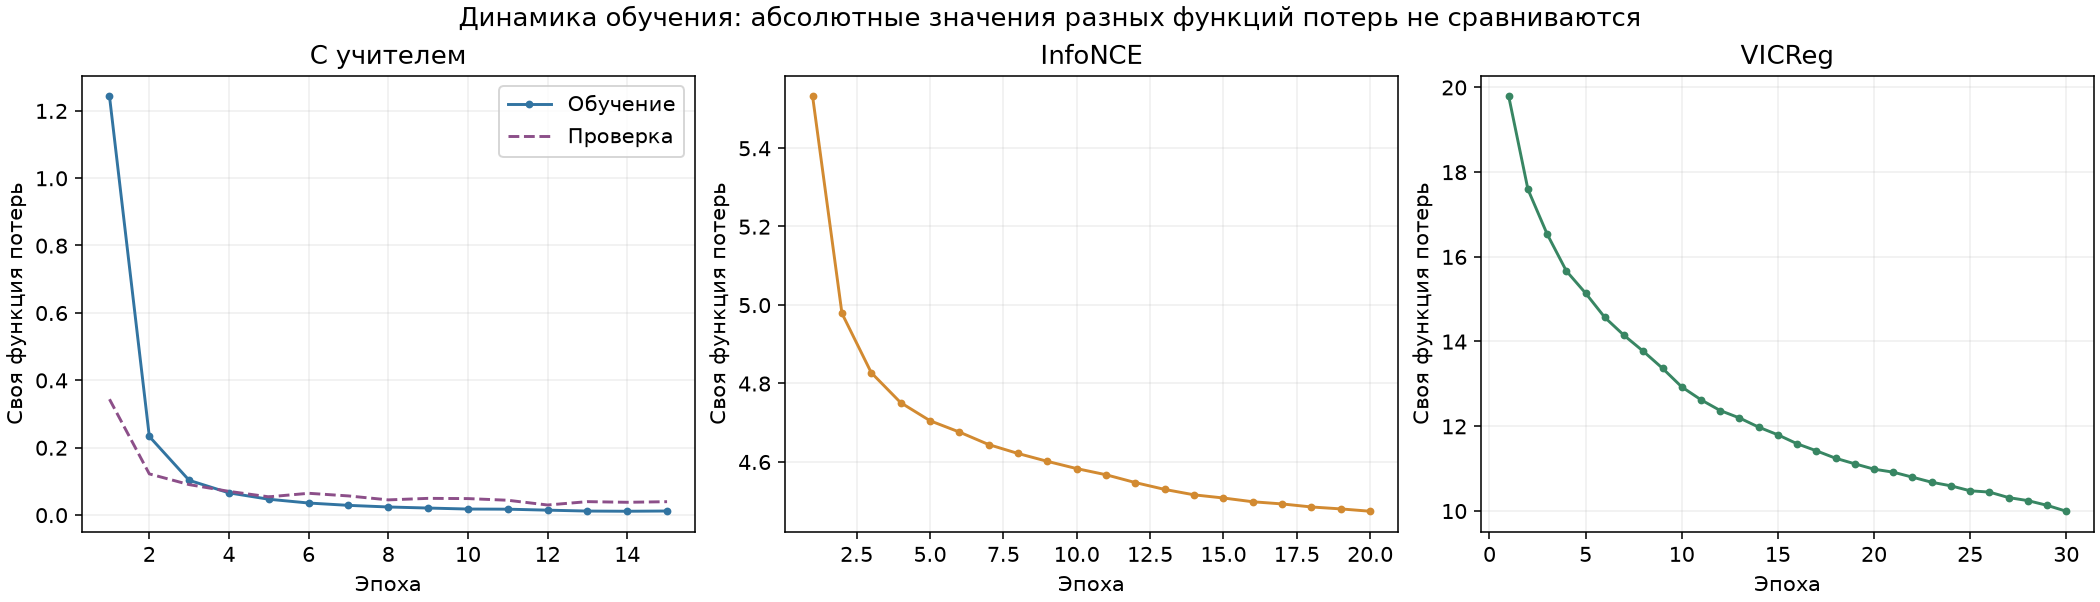

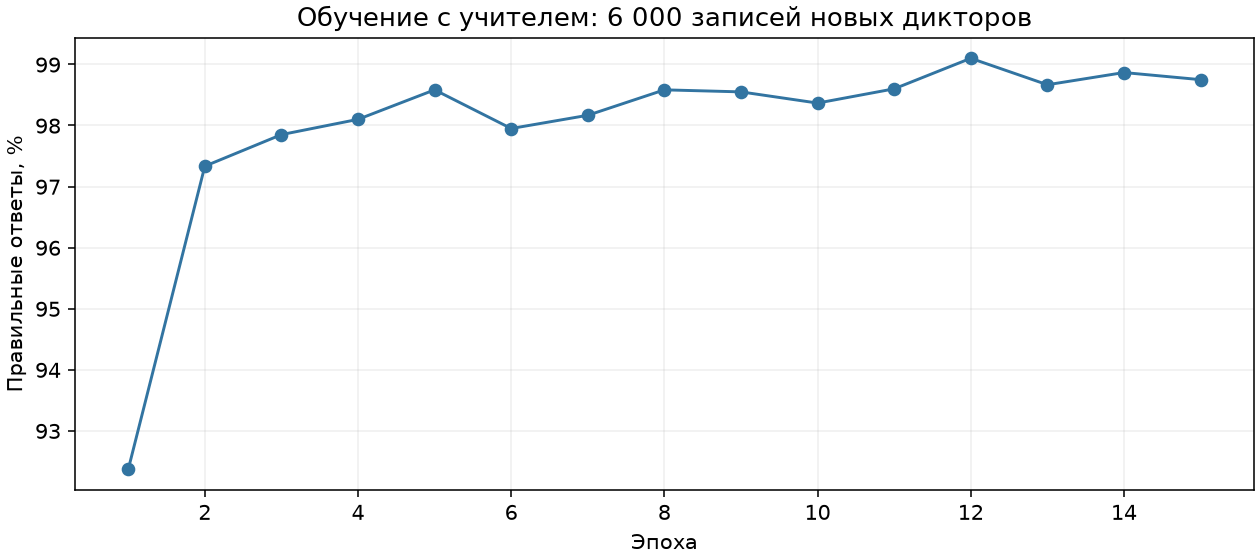

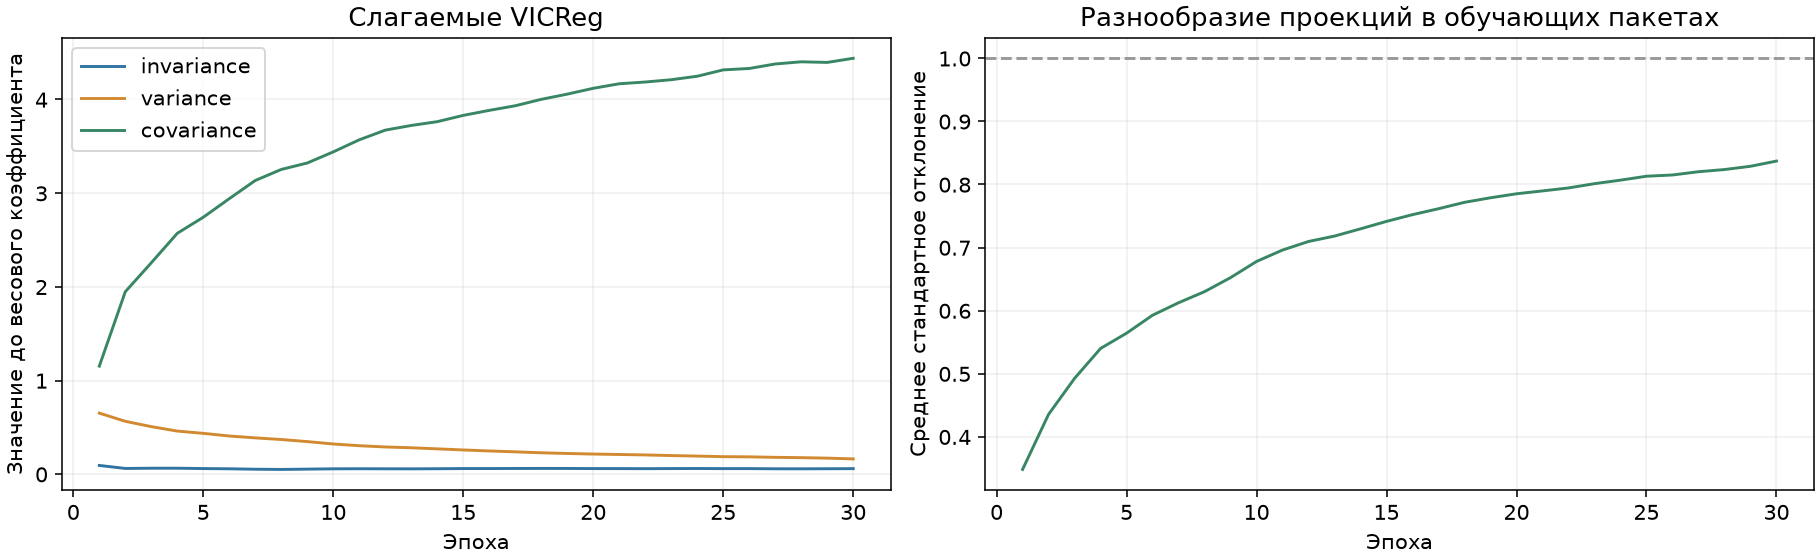

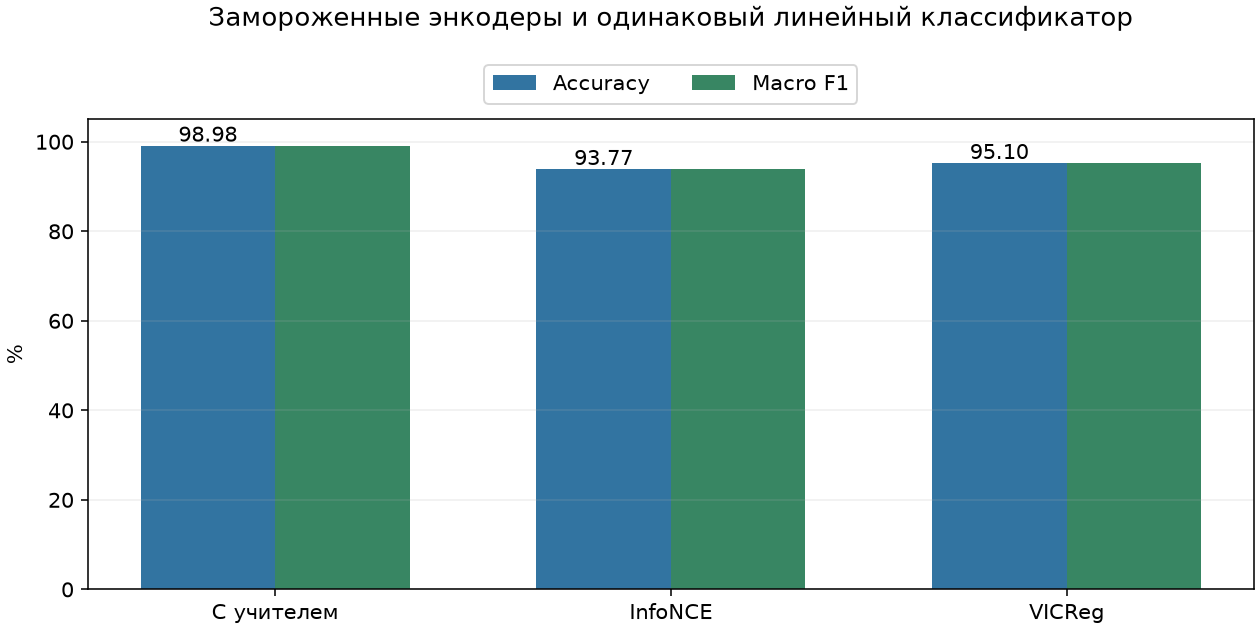

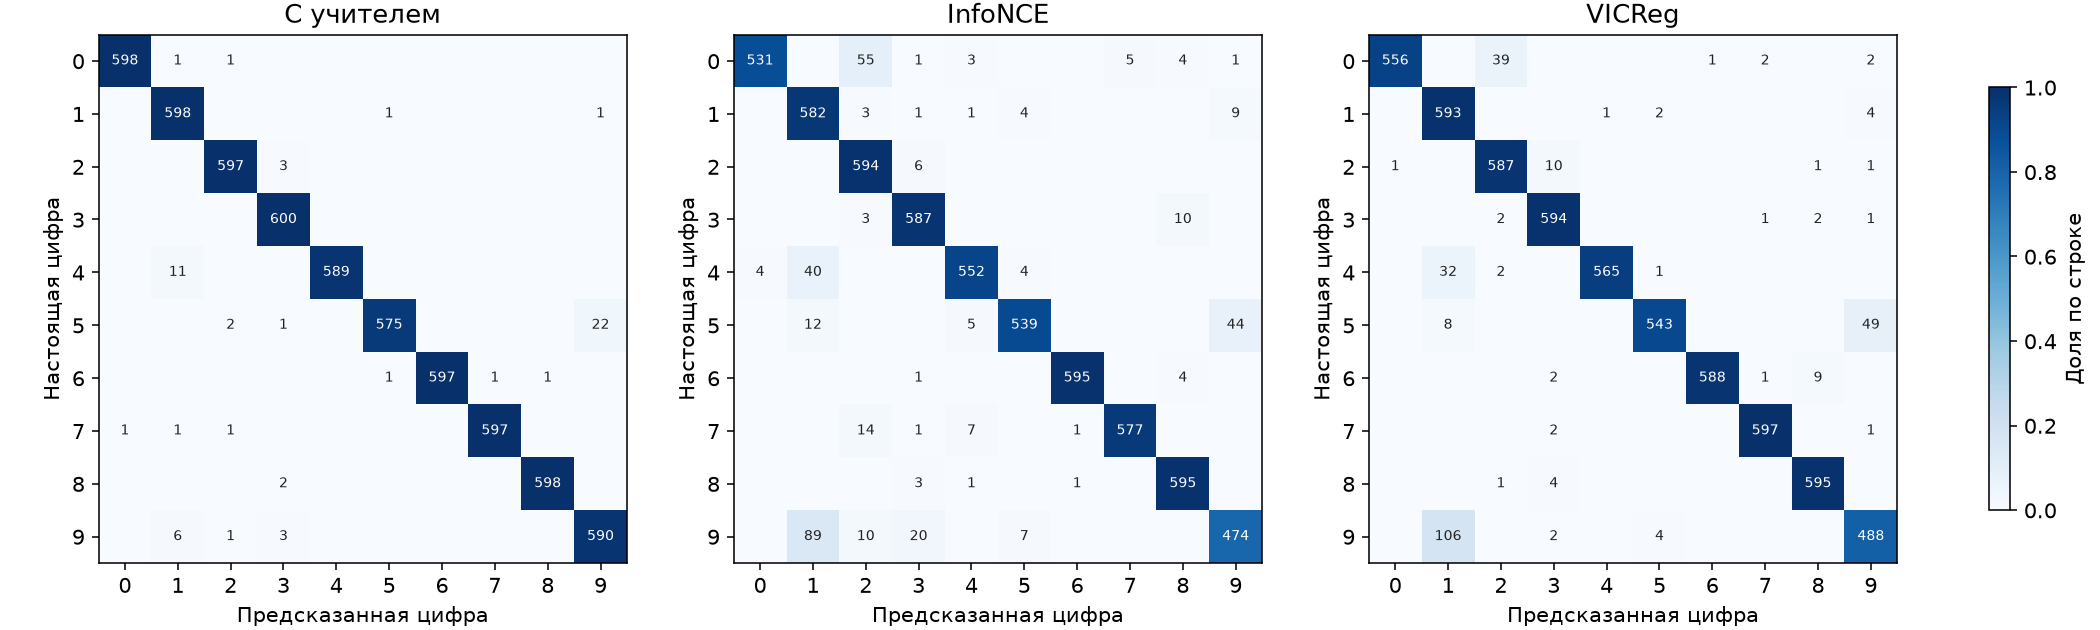

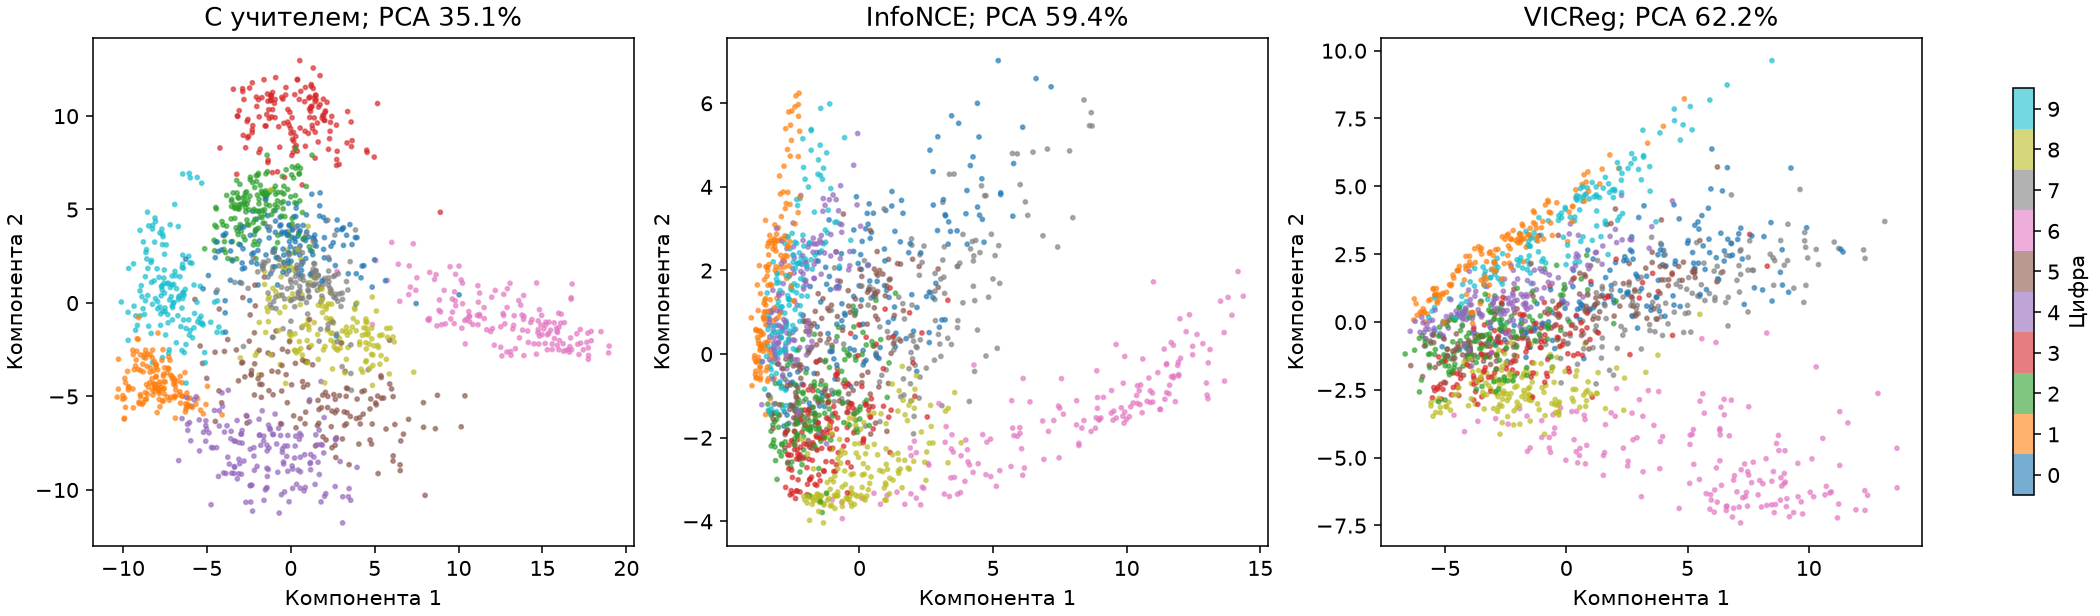

In [7]:
from IPython.display import display, Image
display(Image(filename=str(FIG/'training_losses.png'),width=1100))
display(Image(filename=str(FIG/'supervised_validation.png'),width=1100))
display(Image(filename=str(FIG/'vicreg_components.png'),width=1100))
display(Image(filename=str(FIG/'comparison.png'),width=1100))
display(Image(filename=str(FIG/'confusions.png'),width=1100))
display(Image(filename=str(FIG/'embeddings_pca.png'),width=1100))

## 4. Одинаковое сравнение трёх подходов

После обучения веса энкодеров заморожены. Для каждого подхода я извлёк по 128 признаков — объединение двух ветвей — и обучил одинаковый StandardScaler + LogisticRegression с C=1 на 24 000 обучающих записях. Значения признаков у методов различаются; размер представления и процедура проверки одинаковы. Нормировка и классификатор не обучаются на validation. Метки нужны SSL-подходам только на этом этапе линейной проверки.

| Способ обучения признаков | Верных ответов из 6000 | Accuracy | Macro F1 | Log loss |
|---|---|---|---|---|
| обучение с учителем | 5939 | 98.98% | 0.9898 | 0.0317 |
| InfoNCE | 5626 | 93.77% | 0.9377 | 0.2114 |
| VICReg | 5706 | 95.10% | 0.9513 | 0.1631 |


Accuracy — доля правильных ответов. Macro F1 одинаково учитывает все десять цифр. Log loss учитывает не только выбранный ответ, но и уверенность; для него меньшее значение лучше. Разные обучающие loss нельзя сравнивать по абсолютному числу как показатель качества.

Лучший результат — обучение с учителем: 5939 правильных ответов из 6000. Обучение с учителем напрямую оптимизирует распознавание нужных цифр и использует все обучающие метки уже при настройке энкодеров. SSL-методы сначала решают другую задачу: согласуют два вида записи. Их признаки могут сохранять голос диктора, тембр и другие различия, которые не помогают различать цифры. При большом количестве готовых меток преимущество supervised в таком опыте объяснимо.

На рисунке PCA показана только двумерная проекция признаков, а не дополнительная метрика качества. Точность определялась по всем 128 признакам.

## Что можно заключить

Все три подхода обучены и проверены на одинаковых новых дикторах. Графики показывают динамику обучения, а единая линейная проверка — насколько признаки полезны для распознавания цифр.

Это один запуск с фиксированным seed, без перебора параметров и без отдельного тестового набора. Время обучения и число эпох у подходов отличаются. Для линейной проверки использованы все обучающие метки, поэтому эксперимент не измеряет преимущество SSL при недостатке разметки. Сужение сетей и уменьшенный проектор ограничивают перенос выводов на полноразмерные модели. Полученная точность не означает такой же результат на произвольной речи, другом языке или другом микрофоне.

Публикация решения в GitHub не подтверждает сдачу в eLearn. Правило пересчёта этих работ в 40% онлайн-курса и замена сертификата пока не установлены.